In [1]:
import torch
import torch.nn 
import numpy as np 
import pandas as pd 
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
import sklearn._config

In [2]:
raw_x,y = load_wine(return_X_y=True,as_frame=True)

In [3]:
sklearn._config.set_config(transform_output="pandas")

col_t = make_column_transformer(
(StandardScaler(),list(raw_x.select_dtypes(include='number')))
)
transformed_data = col_t.fit_transform(raw_x)


sklearn._config.set_config(transform_output="default")



In [4]:
transformed_data

,standardscaler__alcohol,standardscaler__malic_acid,standardscaler__ash,standardscaler__alcalinity_of_ash,standardscaler__magnesium,standardscaler__total_phenols,standardscaler__flavanoids,standardscaler__nonflavanoid_phenols,standardscaler__proanthocyanins,standardscaler__color_intensity,standardscaler__hue,standardscaler__od280/od315_of_diluted_wines,standardscaler__proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,0.876275,2.974543,0.305159,0.301803,-0.332922,-0.985614,-1.424900,1.274310,-0.930179,1.142811,-1.392758,-1.231206,-0.021952
174,0.493343,1.412609,0.414820,1.052516,0.158572,-0.793334,-1.284344,0.549108,-0.316950,0.969783,-1.129518,-1.485445,0.009893
175,0.332758,1.744744,-0.389355,0.151661,1.422412,-1.129824,-1.344582,0.549108,-0.422075,2.224236,-1.612125,-1.485445,0.280575
176,0.209232,0.227694,0.012732,0.151661,1.422412,-1.033684,-1.354622,1.354888,-0.229346,1.834923,-1.568252,-1.400699,0.296498


In [5]:
y[y!=2].index

Index([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,
       ...
       120, 121, 122, 123, 124, 125, 126, 127, 128, 129],
      dtype='int64', length=130)

In [6]:
y = y[y[y!=2].index]

In [7]:
transformed_data = transformed_data.iloc[y.index]

In [8]:
transformed_data

,standardscaler__alcohol,standardscaler__malic_acid,standardscaler__ash,standardscaler__alcalinity_of_ash,standardscaler__magnesium,standardscaler__total_phenols,standardscaler__flavanoids,standardscaler__nonflavanoid_phenols,standardscaler__proanthocyanins,standardscaler__color_intensity,standardscaler__hue,standardscaler__od280/od315_of_diluted_wines,standardscaler__proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874
...,...,...,...,...,...,...,...,...,...,...,...,...,...
125,-1.149560,-0.158301,-0.718336,0.451946,-1.035055,0.488531,0.623193,0.065639,-0.422075,-0.994085,-0.427544,0.943956,-1.174738
126,-0.704864,-0.723829,-0.279695,0.602088,-0.964842,0.712858,1.125176,0.226796,0.313800,-0.483652,-1.173391,0.322481,-1.257535
127,-1.495434,-0.185231,1.511422,2.704083,-0.543562,-0.264565,0.211566,1.757779,0.296279,-0.890268,0.055064,-0.242496,-0.894503
128,-0.778980,-0.634063,-0.243142,1.502943,-0.824415,-0.120355,0.422399,0.307374,0.541571,-1.270929,-0.295924,0.237735,-1.289380


In [9]:
X_train,X_test,y_train,y_test = train_test_split(transformed_data,y,stratify=y,test_size=0.2,random_state=1)

In [10]:
X_train_tensor = torch.from_numpy(X_train.to_numpy()).float()
X_test_tensor = torch.from_numpy(X_test.to_numpy()).float()
y_train_tensor = torch.from_numpy(y_train.to_numpy()).float()
y_test_tensor = torch.from_numpy(y_test.to_numpy()).float()

In [11]:
class LogisiticRegressor(torch.nn.Module):
    def __init__(self,num_of_inputs,num_of_neurons_h,hidden_layer_size):
        super(LogisiticRegressor,self).__init__()
        self.network = torch.nn.Sequential(
            torch.nn.utils.parametrizations.weight_norm(torch.nn.Linear(num_of_inputs,num_of_neurons_h,bias=True)),
            torch.nn.Tanh(),
            *(torch.nn.utils.parametrizations.weight_norm(torch.nn.Linear(num_of_neurons_h,num_of_neurons_h,bias=True)) for _ in range(hidden_layer_size)),
            torch.nn.Tanh(),
            torch.nn.utils.parametrizations.weight_norm(torch.nn.Linear(num_of_neurons_h,1,bias=True)),
            torch.nn.Sigmoid()                   
        )
    def forward(self,x):
        return self.network(x)
    def predict(self,x):
        with torch.no_grad():
            return self.forward(x) 
    def train(self,X,y,num_of_epoch=50,batch_size=10,learning_rate=.01):
        cost = []
        cost.clear()
        loss = torch.nn.BCELoss() 
        optimizer = torch.optim.AdamW(self.parameters(),lr=learning_rate)
        torch.manual_seed(1)
        for epoch in range(num_of_epoch):
            perm_idx = torch.randperm(X.size(0))
            batches = torch.split(perm_idx,batch_size)
            for batch in batches:
                y_pred = self.forward(X[batch]).flatten()
                current_loss = loss(y_pred,y[batch])
                current_loss.backward()
            cost.append(current_loss.item())
            optimizer.step()
            optimizer.zero_grad()
        return cost
    def score(self,X,y):
        with torch.no_grad():
            y_hat:torch.Tensor = self.forward(X).float().round().flatten()
            return y_hat.eq(y).float().mean().item()
            

In [12]:
model = LogisiticRegressor(num_of_inputs=X_train_tensor.size(1),num_of_neurons_h=2*X_train_tensor.size(1),hidden_layer_size=2)

In [13]:
costs = model.train(X_train_tensor,y_train_tensor,num_of_epoch=30,batch_size=10,learning_rate=.01)

In [14]:
model.score(X_test_tensor,y_test_tensor)

1.0

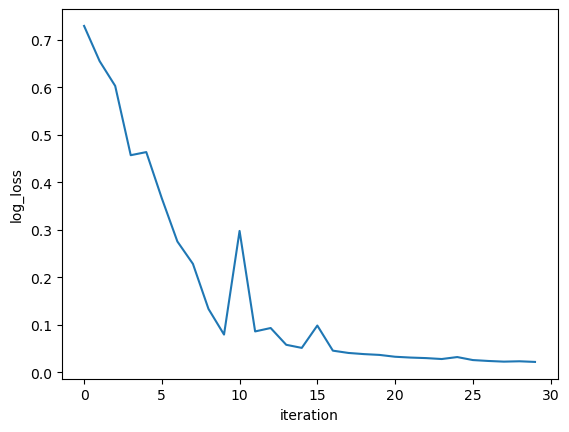

In [15]:
import matplotlib.pyplot as plt 

plt.plot(costs)
plt.xlabel('iteration')
plt.ylabel('log_loss')
plt.show()